# Évaluation du modèle

Mélange d'un ridge pondéré par date et d'une maximisation directe du cosinus avec lissage.
Description mathématique : voir le `README.md` à la racine du dépôt.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qrt_model import (load_data, score, check_stiefel, fit, fit_ridge, ridge_w, cos_w, blend_w,
                       cv_repeated, summary, read_submission)

X, y, stock_id, date = load_data("../data")
assert X.shape == (25200, 250) and y.shape == (25200,)
print(X.shape, y.shape)

(25200, 250) (25200,)


In [2]:
# composantes du mélange (normalisées) et poids finaux
w_ridge = ridge_w(X, y)
w_ridge /= np.linalg.norm(w_ridge)
w_cos = cos_w(X, y, w0=w_ridge)
w = blend_w(X, y)
assert np.allclose(w, w_ridge + w_cos)
print("cosinus entre les deux composantes :", round(w_ridge @ w_cos, 3))

cosinus entre les deux composantes : 0.939


In [3]:
# score in-sample (50 actions d'entraînement)
A, beta = fit(X, y)
assert check_stiefel(A)
assert np.allclose(A @ beta, w)
in_sample = {"ridge pondéré": score(y, X @ w_ridge), "cosinus lissé": score(y, X @ w_cos), "mélange": score(y, X @ w)}
pd.Series(in_sample).round(4)

ridge pondéré    0.1407
cosinus lissé    0.1478
mélange          0.1462
dtype: float64

In [4]:
# validation croisée entre actions : 5 découpages x 5 plis, gains appariés vs ridge pondéré
s_ridge = cv_repeated(fit_ridge, X, y, stock_id)
s_model = cv_repeated(fit, X, y, stock_id)
res = pd.DataFrame({"ridge pondéré": summary(s_ridge), "mélange": summary(s_model, s_ridge)}).T
assert res.loc["mélange", "gain"] > 2 * res.loc["mélange", "se_gain"]
res.round(4)

,cv,se,gain,se_gain
ridge pondéré,0.0521,0.0052,NaN,NaN
mélange,0.0557,0.0058,0.0037,0.0013


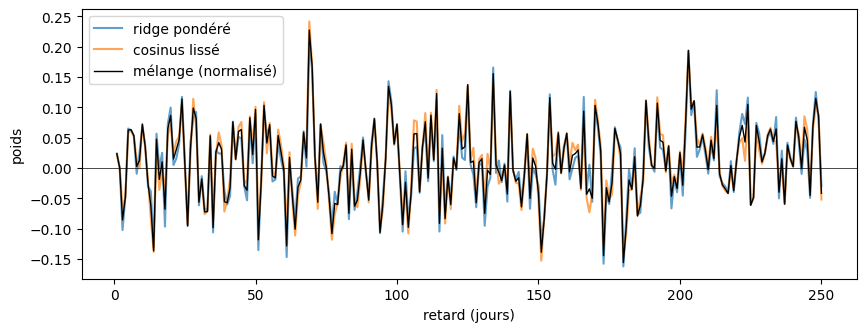

In [5]:
# poids par retard
plt.figure(figsize=(10, 3.5))
lags = np.arange(1, 251)
plt.plot(lags, w_ridge, alpha=0.7, label="ridge pondéré")
plt.plot(lags, w_cos, alpha=0.7, label="cosinus lissé")
plt.plot(lags, w / np.linalg.norm(w), color="k", lw=1, label="mélange (normalisé)")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("retard (jours)")
plt.ylabel("poids")
plt.legend()
plt.show()

In [6]:
# le fichier soumis correspond au modèle
A_sub, beta_sub = read_submission("../soumission/soumission_modele4.csv")
assert check_stiefel(A_sub)
assert np.allclose(A_sub, A) and np.allclose(beta_sub, beta)
print("soumission conforme, score in-sample :", round(score(y, X @ A_sub @ beta_sub), 4))

soumission conforme, score in-sample : 0.1462
